## Step 1 : EDA
+ #### Exploratory Data Analysis

#### 1.1 DataSet Structure :  

##### Libraries & Tools Used:

1. Pandas (pd): Used for data loading, manipulation, and structural analysis.

2. NumPy (np): Used for numerical operations and array manipulations.

3. Matplotlib (plt) & Seaborn (sns): Used for data visualization, plotting distributions, and detecting outliers and missing value patterns.

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
df = pd.read_csv("credit_risk.csv")
df.head()

,Id,Age,Income,Home,Emp_length,Intent,Amount,Rate,Status,Percent_income,Default,Cred_length
0,0,22,59000,RENT,123.0,PERSONAL,35000,16.02,1,0.59,Y,3
1,1,21,9600,OWN,5.0,EDUCATION,1000,11.14,0,0.10,N,2
2,2,25,9600,MORTGAGE,1.0,MEDICAL,5500,12.87,1,0.57,N,3
3,3,23,65500,RENT,4.0,MEDICAL,35000,15.23,1,0.53,N,2
4,4,24,54400,RENT,8.0,MEDICAL,35000,14.27,1,0.55,Y,4


+ the dataset contains exactly 32,581 rows (observations) and 12 columns (variables).

In [39]:
df.shape

(32581, 12)

+ 12 variables present in the dataset: Id, Age, Income, Home, Emp_length, Intent, Amount, Rate, Status, Percent_income, Default, and Cred_length

In [78]:
df.columns

Index(['Id', 'Age', 'Income', 'Home', 'Emp_length', 'Intent', 'Amount', 'Rate',
       'Status', 'Percent_income', 'Default', 'Cred_length'],
      dtype='str')

+ I converted the **Id** column to string type to prevent pandas from treating it as a numerical variable during **statistical calculations** and **correlation analysis**. This ensures that unique identifiers do not skew our data insights.

In [40]:
df['Id'] = df['Id'].astype(str)

+ initial details confirm the overall structure of the DataFrame, showing a total of 32,581 entries indexed from 0 to 32,580. we have 3 float, 5 integer and 4 strings


In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              32581 non-null  str    
 1   Age             32581 non-null  int64  
 2   Income          32581 non-null  int64  
 3   Home            32581 non-null  str    
 4   Emp_length      31686 non-null  float64
 5   Intent          32581 non-null  str    
 6   Amount          32581 non-null  int64  
 7   Rate            29465 non-null  float64
 8   Status          32581 non-null  int64  
 9   Percent_income  32581 non-null  float64
 10  Default         32581 non-null  str    
 11  Cred_length     32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


+ A statistical summary of all numerical columns in the DataFrame, including key metrics like count, mean, standard deviation, minimum, quartiles, and maximum values.

In [42]:
df.describe()

,Age,Income,Emp_length,Amount,Rate,Status,Percent_income,Cred_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


#### 1.2 Missing Values and Duplicate Values

+ How many Missing Value in each variable

In [81]:
df.isnull().sum().sort_values(ascending=False)

Rate              3116
Emp_length         895
Id                   0
Age                  0
Home                 0
Income               0
Intent               0
Amount               0
Status               0
Percent_income       0
Default              0
Cred_length          0
dtype: int64

+ *12,31%* of Data is a Missing Values

In [95]:
df.isnull().mean().sort_values(ascending=False) * 100

Rate              9.563856
Emp_length        2.747000
Id                0.000000
Age               0.000000
Home              0.000000
Income            0.000000
Intent            0.000000
Amount            0.000000
Status            0.000000
Percent_income    0.000000
Default           0.000000
Cred_length       0.000000
dtype: float64

+ Zero duplicate

In [89]:
sum(df.duplicated())

0

+ How many unique value in each colmuns

In [90]:
df.nunique().sort_values(ascending=False)

Id                32581
Income             4295
Amount              753
Rate                348
Percent_income       77
Age                  58
Emp_length           36
Cred_length          29
Intent                6
Home                  4
Status                2
Default               2
dtype: int64

+ Visualisation of Missing Values

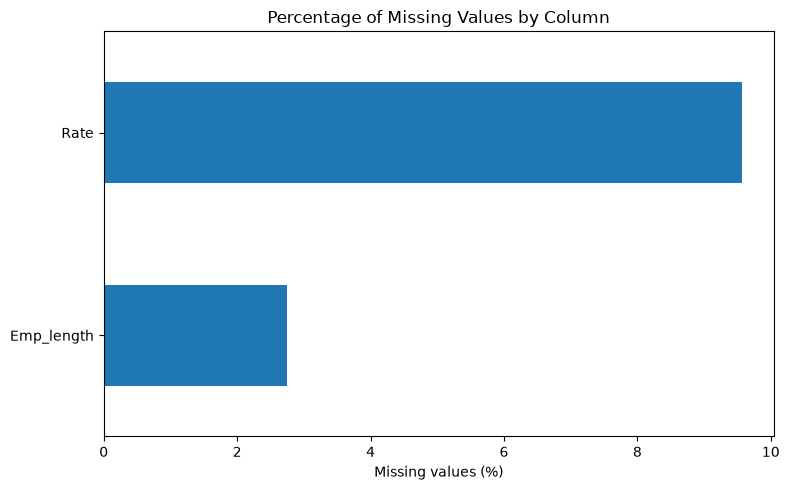

In [ ]:
missing_pct = df.isnull().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0].sort_values()

missing_pct.plot(kind="barh", figsize=(8, 5))

plt.xlabel("Missing values (%)")
plt.title("Percentage of Missing Values by Column")
plt.tight_layout()
plt.show()

#### 1.3 Numerical valor analysis : 

In [119]:
num_cols = ['Age', 'Income', 'Emp_length', 'Amount', 'Rate', 'Percent_income', 'Cred_length']

##### *Describe of Numerical columns*
+ Target variable (Default): Encoded in binary (Y=1, N=0) for classification.
+ Outliers (Age = 123/144, Emp_length = 123): These are error codes (sentinels). They were replaced by the median of their column to avoid biasing the models

In [113]:
df[['Age', 'Income', 'Emp_length', 'Amount', 'Rate']].describe()

,Age,Income,Emp_length,Amount,Rate
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000


+ Each Numerical columns Histograme

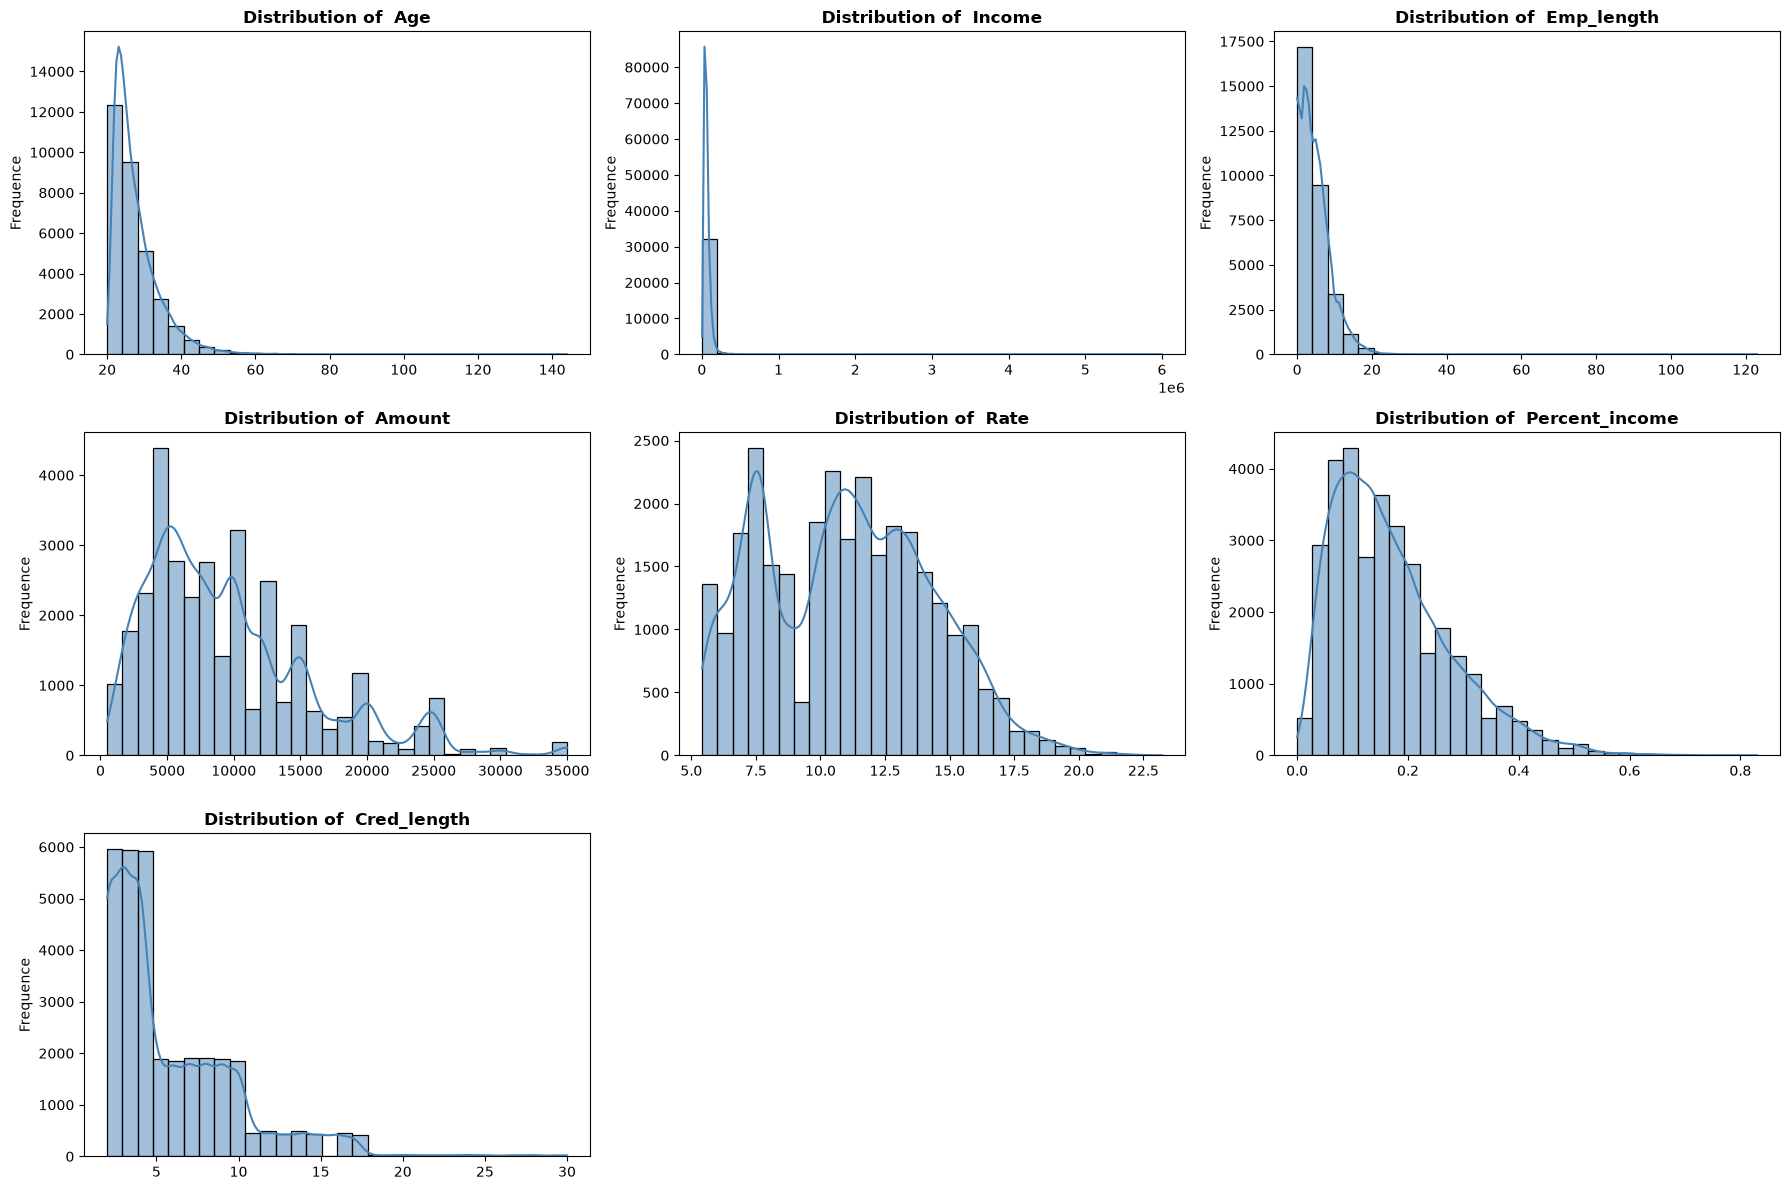

In [123]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribution of  {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequence')

for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### 1.4 categorical columns analysis : 

In [125]:
cat_cols = ['Default', 'Home', 'Intent']

In [ ]:
print(df["Intent"].value_counts(normalize=True))
print("UwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwU")
print(df["Home"].value_counts(normalize=True))

Intent
EDUCATION            0.198060
MEDICAL              0.186336
VENTURE              0.175532
PERSONAL             0.169455
DEBTCONSOLIDATION    0.159971
HOMEIMPROVEMENT      0.110647
Name: proportion, dtype: float64
UwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUwUw
Home
RENT        0.504773
MORTGAGE    0.412633
OWN         0.079310
OTHER       0.003284
Name: proportion, dtype: float64
